In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [21]:
# Load dataset
df = pd.read_csv("cleaned_dataset.csv")
target = "Retard moyen de tous les trains à l'arrivée"
y = df[target]

In [22]:
# Date feature engineering
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["month"] = df["Date"].dt.month

features = [
    "Durée moyenne du trajet",
    "Nombre de circulations prévues",
    "Nombre de trains annulés",
    "month",
    "Nombre trains en retard > 15min",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min",
    "Service"
]
X = df[features]

In [23]:
# Encode categorical variable
X = pd.get_dummies(X, drop_first=True)

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [24]:
# Optimized Random Forest
model = RandomForestRegressor(
    n_estimators=200,        
    max_depth=15,            
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

# Predictions
predictions = model.predict(X_test)

# Metrics
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("\nRandom Forest Performance:")
print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)


Random Forest Performance:
RMSE: 1.4773545111077233
MAE: 1.0083863261836623
R²: 0.864249904851183


Text(0.5, 1.0, 'Random Forest - Actual vs Predicted')

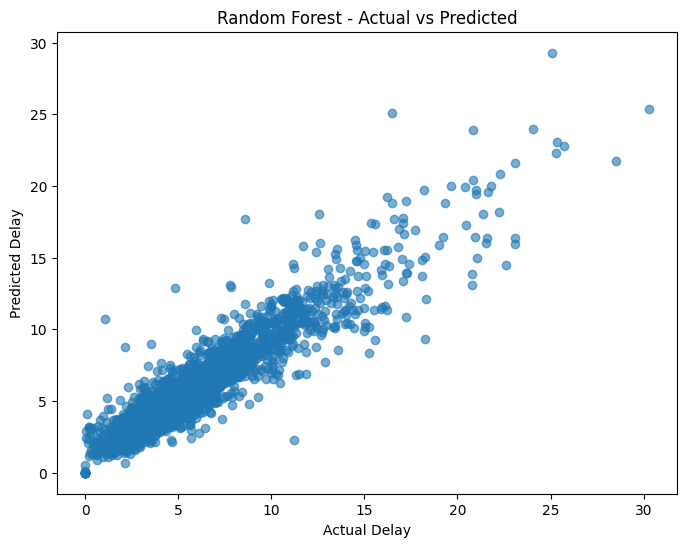

In [25]:
# Regression Graph
plt.figure(figsize=(8,6))
plt.scatter(y_test, predictions, alpha=0.6)
plt.xlabel("Actual Delay")
plt.ylabel("Predicted Delay")
plt.title("Random Forest - Actual vs Predicted")

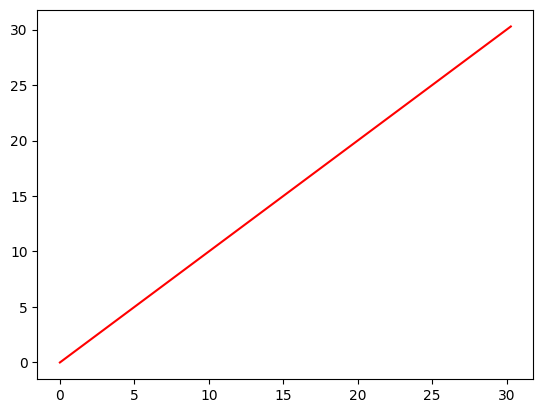

['model_features.pkl']

In [26]:
# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)
plt.show()

# Save lightweight model
joblib.dump(model, "linear_delay_model.pkl")
joblib.dump(X.columns, "model_features.pkl")

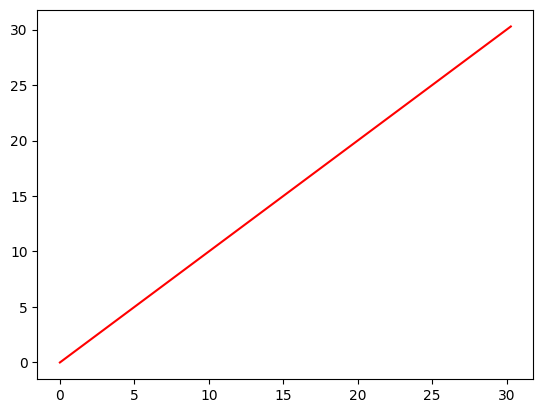


Top 10 Most Important Features:
Nombre de circulations prévues     0.349515
Nombre trains en retard > 60min    0.195220
Nombre trains en retard > 30min    0.148546
Nombre trains en retard > 15min    0.129861
Durée moyenne du trajet            0.124884
Nombre de trains annulés           0.035168
month                              0.013903
Service_National                   0.002706
Service_Unknown                    0.000197
dtype: float64


['model_features.pkl']

In [27]:
# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)
plt.show()

# Feature importance
importances = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)
print("\nTop 10 Most Important Features:")
print(importances.head(10))

# Save model
joblib.dump(model, "rf_delay_model.pkl")
joblib.dump(X.columns, "model_features.pkl")

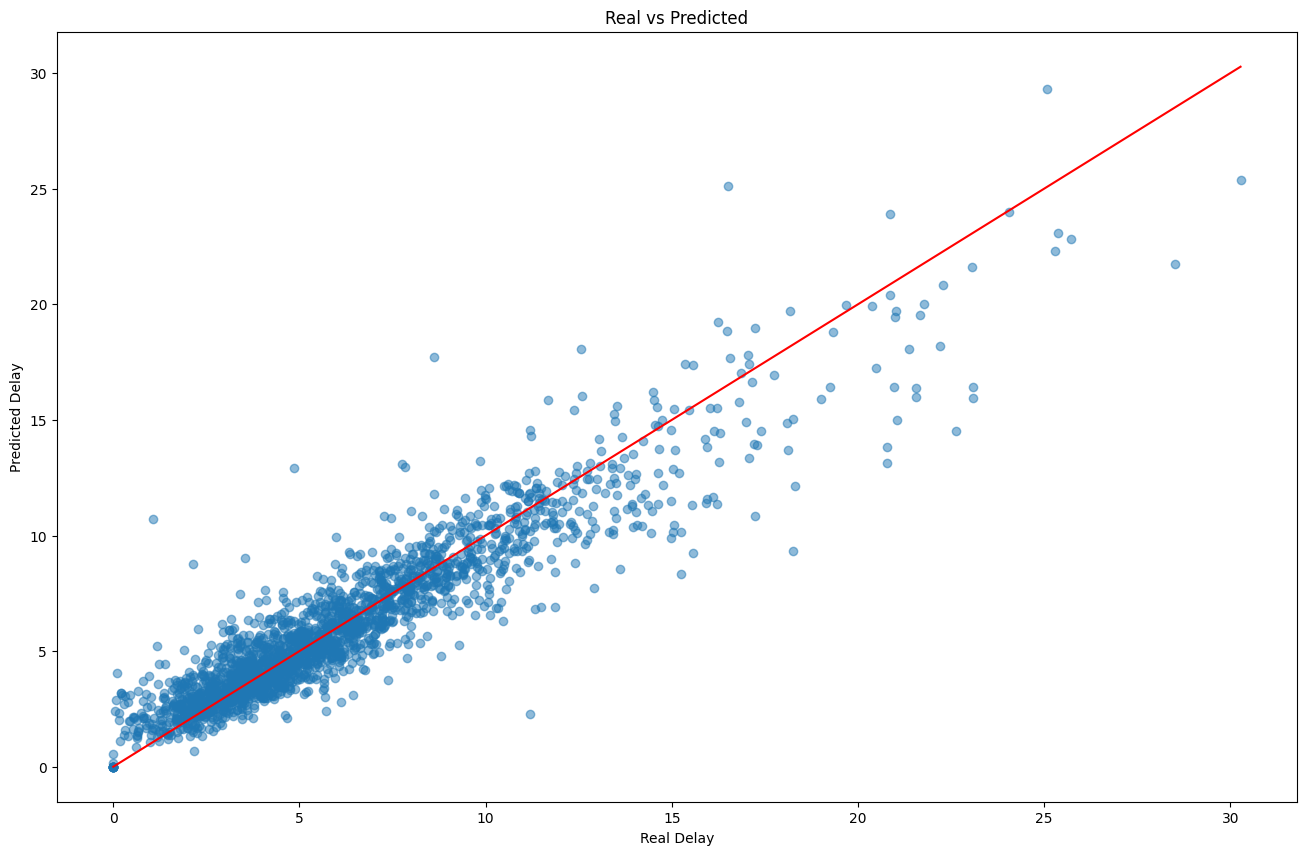

In [28]:
y_pred = model.predict(X_test)

plt.figure(figsize=(16,10))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Real Delay")
plt.ylabel("Predicted Delay")
plt.title("Real vs Predicted")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.show()